In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import display

import gdp_analysis
from gdp_analysis.load import load_gdp
from gdp_analysis.clean import clean_gdp, summarise_gdp
from gdp_analysis.plot import plot_gdp

ROOT = Path(gdp_analysis.__file__).resolve().parents[1]
print("Project folder:", ROOT)

Project folder: /home/zl685/D100_PS1/D100-PS1-Ex2


In [2]:
raw = load_gdp(ROOT / "data" / "raw" / "gdp_raw.json")
data = clean_gdp(raw)

expected_countries = {
    "GBR", "USA", "BRA", "JPN", "CHN", "DEU", "CHE"
}

assert set(data["country_code"]) == expected_countries
assert len(data) == 7 * 23
assert data["gdp"].gt(0).all()

display(
    data.groupby("country")["year"].agg(["min", "max", "count"])
)

output_folder = ROOT / "data" / "processed"
output_folder.mkdir(parents=True, exist_ok=True)

data.to_csv(output_folder / "gdp_clean.csv", index=False)

,min,max,count
country,,,
Brazil,2000,2022,23
China,2000,2022,23
Germany,2000,2022,23
Japan,2000,2022,23
Switzerland,2000,2022,23
United Kingdom,2000,2022,23
United States,2000,2022,23


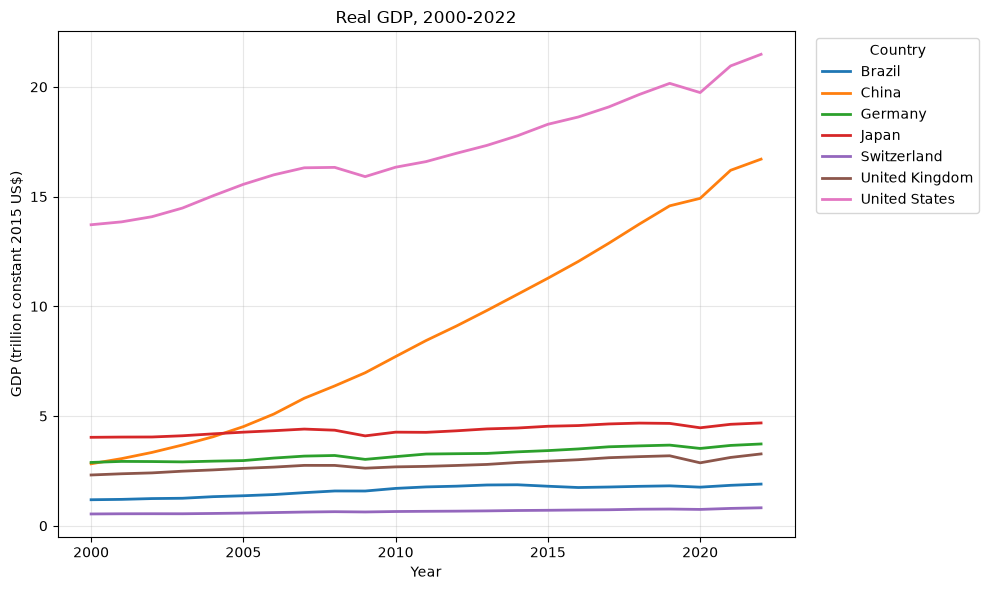

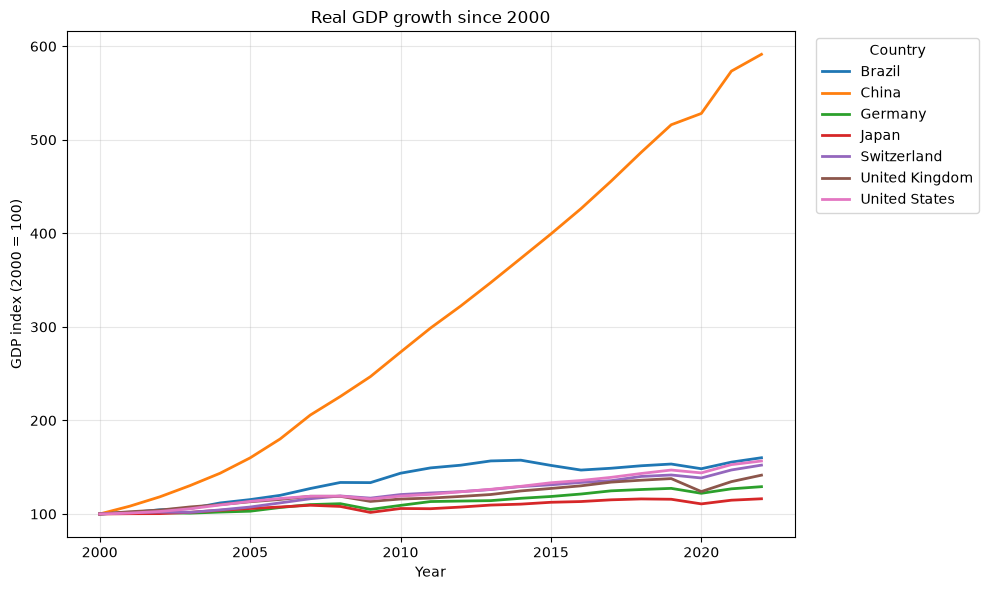

In [3]:
figure_folder = ROOT / "figures"
figure_folder.mkdir(parents=True, exist_ok=True)

fig, ax = plot_gdp(data)
fig.savefig(
    figure_folder / "gdp_levels.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

fig, ax = plot_gdp(data, indexed=True)
fig.savefig(
    figure_folder / "gdp_index.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

In [4]:
summary = summarise_gdp(data)
display(summary.round(2))

for country, row in summary.iterrows():
    print(
        f"{country}: real GDP changed by "
        f"{row['change_percent']:.1f}% between 2000 and 2022."
    )

,GDP_2000_trillion,GDP_2022_trillion,change_percent
country,,,
China,2.82,16.71,491.40
Brazil,1.19,1.90,60.10
United States,13.72,21.48,56.61
Switzerland,0.54,0.82,52.21
United Kingdom,2.31,3.27,41.48
Germany,2.89,3.73,29.17
Japan,4.03,4.69,16.24


China: real GDP changed by 491.4% between 2000 and 2022.
Brazil: real GDP changed by 60.1% between 2000 and 2022.
United States: real GDP changed by 56.6% between 2000 and 2022.
Switzerland: real GDP changed by 52.2% between 2000 and 2022.
United Kingdom: real GDP changed by 41.5% between 2000 and 2022.
Germany: real GDP changed by 29.2% between 2000 and 2022.
Japan: real GDP changed by 16.2% between 2000 and 2022.
